# 第097讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: [build path redacted]


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "length_accuracy": {
    "6": 1.0,
    "12": 0.0,
    "24": 1.0,
    "48": 0.2734375
  },
  "manual_hidden_states": [
    0.0,
    0.139092447878458,
    -0.0004537760296249044,
    0.2726950775289676
  ],
  "manual_loss": 0.03718130265426482,
  "manual_dw": 0.017440088303720087,
  "finite_difference_error": 7.284766539994436e-12,
  "autograd_error": 0.0,
  "reset_vs_leaked_max_logit_difference": 3.803727865219116,
  "truncate_forward_max_error": 0.0,
  "truncate_gradient_max_difference": 2.1166950318729505e-05,
  "seconds": 1.6374161989997447,
  "environment": {
    "python": "3.12.14",
    "torch": "2.14.1+cpu",
    "numpy": "2.3.5",
    "device": "cpu",
    "threads": 1
  }
}

Script exit: 0


In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_bptt_finite_difference (test_experiment.TestMechanism.test_bptt_finite_difference) ... ok
test_first_bit_label (test_experiment.TestMechanism.test_first_bit_label) ... ok
test_parameter_count (test_experiment.TestMechanism.test_parameter_count) ... ok
test_reset_batch_independence (test_experiment.TestMechanism.test_reset_batch_independence) ... ok
test_truncate_forward_gradient (test_experiment.TestMechanism.test_truncate_forward_gradient) ... ok
test_zero_recurrent_memory (test_experiment.TestMechanism.test_zero_recurrent_memory) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.016s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['length_accuracy', 'manual_hidden_states', 'manual_loss', 'manual_dw', 'finite_difference_error', 'autograd_error', 'reset_vs_leaked_max_logit_difference', 'truncate_forward_max_error', 'truncate_gradient_max_difference', 'seconds', 'environment']


01_training.png
02_memory.png
03_mechanism.png


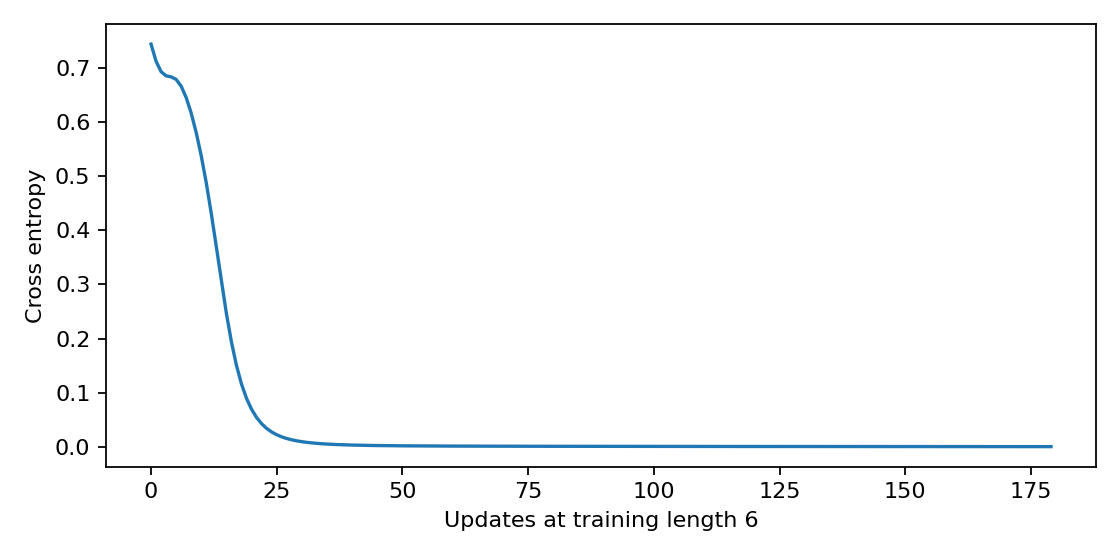

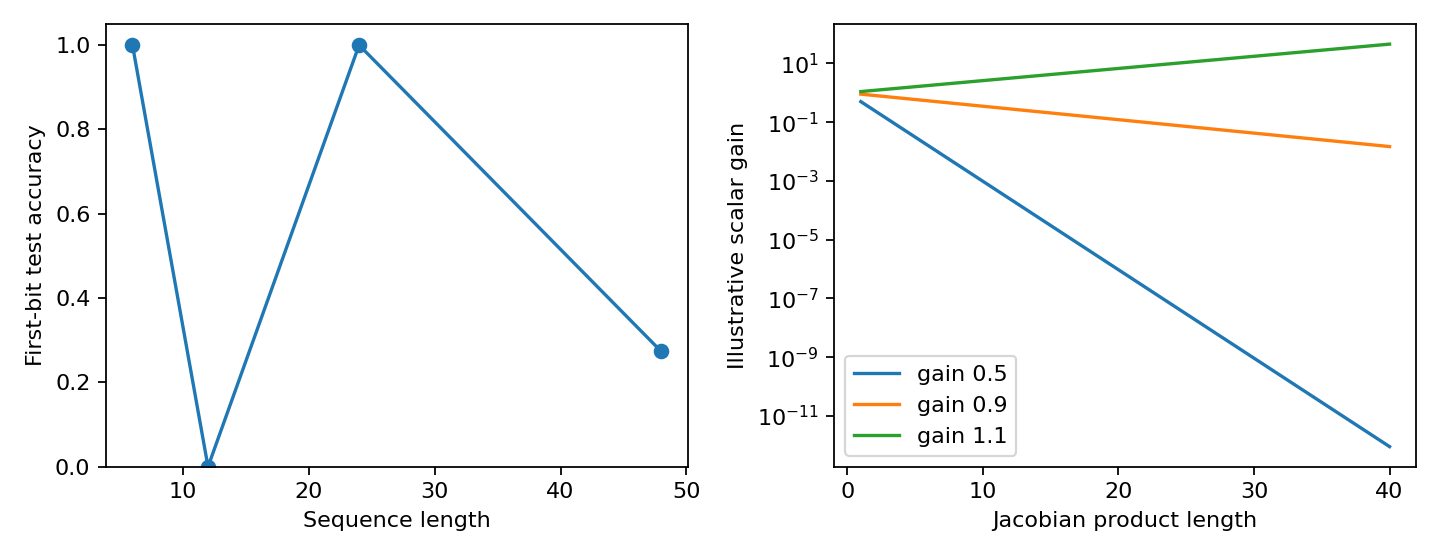

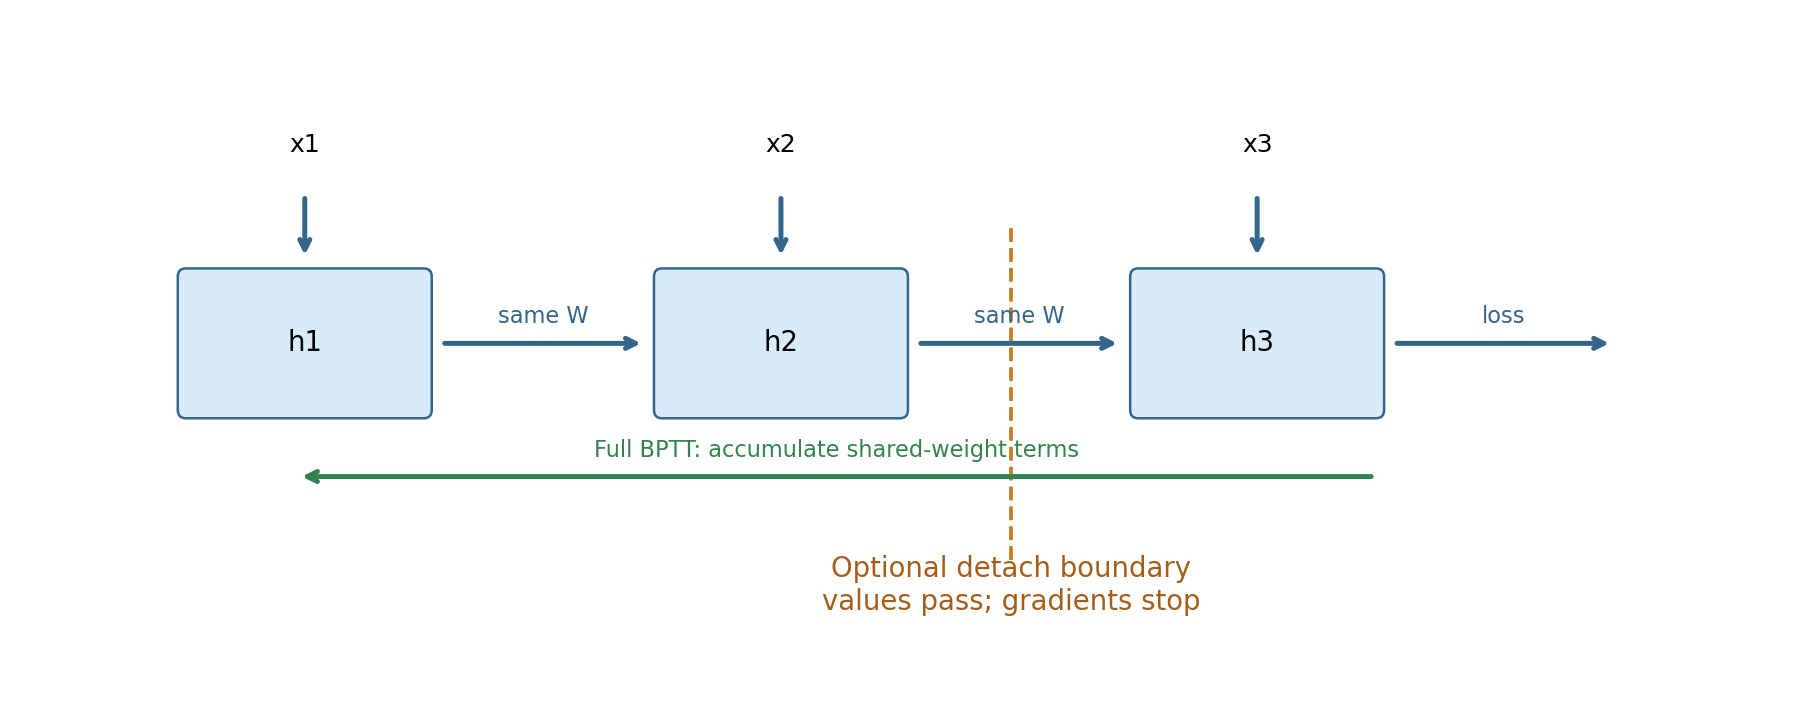

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。